In [7]:
import numpy as np
from scipy.special import lpmv
import matplotlib.pyplot as plt
from matplotlib import colors
import math 

In [2]:
def spherical_harmonics(l,m):
    theta = np.linspace(0,np.pi,200)
    phi   = np.linspace(0,2*np.pi,200,endpoint=False)

    PHI,THETA = np.meshgrid(phi,theta)
    x         = np.cos(THETA)
    P_ml      = lpmv(m,l,x)
    m_abs     = abs(m)

    norm_num  = (2*l + 1)*(math.factorial(l - m_abs))
    norm_denom = 4*np.pi*(math.factorial(l + m_abs))
    normalization = np.sqrt(norm_num/norm_denom)

    phase_factor = phase_term = np.exp(1j*m*PHI)

    Y_positive = normalization*P_ml*phase_factor

    if m < 0:
        Y_lm = (-1)**m_abs * np.conjugate(Y_positive)
    else:
        Y_lm = Y_positive

    return Y_lm,PHI,THETA

In [3]:
def plotting(Y_lm,PHI,THETA):
    probability = np.abs(Y_lm)**2

    plt.figure(figsize=(9, 6))

    plt.pcolormesh(PHI,THETA,probability,shading='auto',cmap='viridis')
    plt.xlabel(r'$\phi$ (radians)')
    plt.ylabel(r'$\theta$ (radians)')
    plt.title(rf'Probability Density $|Y_{{{l}}}^{{{m}}}(\theta,\phi)|^2$')
    plt.colorbar(label=r'$|Y_l^m(\theta,\phi)|^2$')
    plt.xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi],['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
    plt.yticks([0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi],['0', r'$\pi/4$', r'$\pi/2$', r'$3\pi/4$', r'$\pi$'])
    plt.tight_layout()
    plt.show()

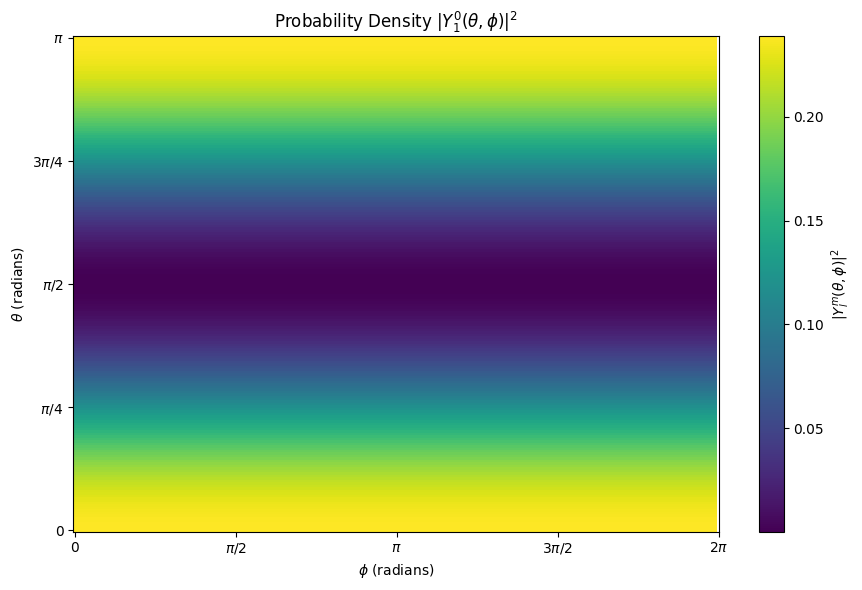

In [5]:
l , m = 1,0
Y_lm,PHI,THETA = spherical_harmonics(l,m)
plotting(Y_lm,PHI,THETA)

In [22]:
def three_d_plot(Y_lm,THETA,PHI):
    probability = np.abs(Y_lm)**2
    R = 1

    x_coor = R*np.sin(THETA)*np.cos(PHI)
    y_coor = R*np.sin(THETA)*np.sin(PHI)
    z_coor = R*np.cos(THETA)
    
    fig = plt.figure(figsize=(8,8))
    ax = fig.add_subplot(111,projection="3d")

    prob_max = np.max(probability)

    if prob_max == 0:
        prob_normalized = np.zeros_like(probability)
    else:
        prob_normalized = probability/prob_max

    cmap = plt.cm.viridis
    face_colors = cmap(prob_normalized)

    ax.plot_surface(x_coor,y_coor,z_coor,facecolors=face_colors,rstride=1,cstride=1,linewidth=0,antialiased=True,shade=False)

    norm = colors.Normalize(vmin=np.min(probability), vmax=np.max(probability))
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    fig.colorbar(sm, ax=ax, shrink=0.7, pad=0.1, label='Probability Density')

    limit = max(np.max(np.abs(x_coor)),np.max(np.abs(y_coor)),np.max(np.abs(z_coor)))

    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_zlim(-limit, limit)
    ax.set_box_aspect((1, 1, 1))

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_title(rf"Angular Probability Density $|Y_{{{l}}}^{{{m}}}(\theta,\phi)|^2$")

    ax.view_init(elev=25, azim=35)
    plt.show()
    

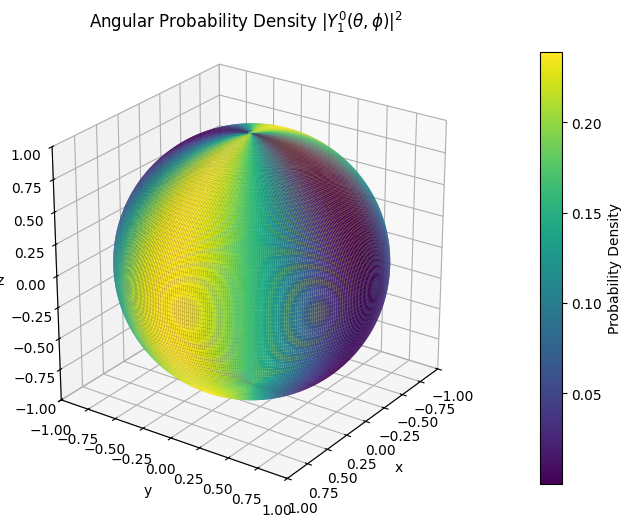

In [23]:
l , m = 1,0
Y_lm,PHI,THETA = spherical_harmonics(l,m)
three_d_plot(Y_lm,PHI,THETA)